# Customer Rating of Breakfast Cereals — K-Means

## Data preprocessing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.width", 88)
raw = pd.read_excel("Cereals_Dataset_63_1.xls").iloc[:, :12]
missing = raw.replace(-1, np.nan).isna().any(axis=1)
print(raw.shape)
print(raw.loc[missing, ["Cereals", "carbo", "sugars", "potass"]].to_string(index=False))

(77, 12)
               Cereals  carbo  sugars  potass
        Almond_Delight   14.0       8     NaN
Cream_of_Wheat_(Quick)   21.0       0     NaN
        Quaker_Oatmeal   -1.0      -1   110.0


In [2]:
df = raw[~missing].reset_index(drop=True)
features = ["calories", "protein", "fat", "sodium", "fiber", "carbo", "sugars", "potass", "vitamins"]
Z = MinMaxScaler().fit_transform(df[features])
print(df.shape)

(74, 12)


## a) K-Means with best K

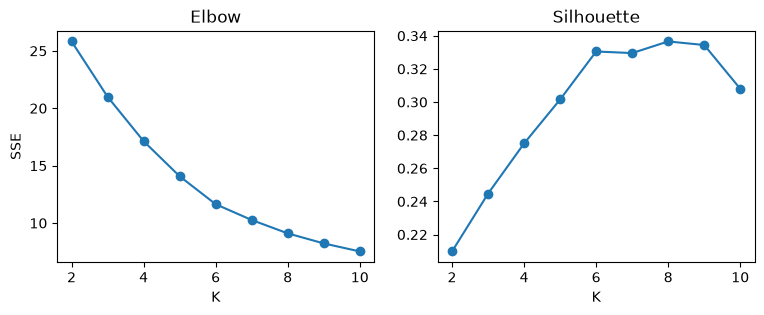

In [8]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(Z)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(ks, inertia, "o-"); ax[0].set(title="Elbow", xlabel="K", ylabel="SSE")
ax[1].plot(ks, sil, "o-"); ax[1].set(title="Silhouette", xlabel="K")
plt.show()

In [4]:
BEST_K = 6
df["cluster"] = KMeans(n_clusters=BEST_K, n_init=50, random_state=42).fit_predict(Z)
profile = df.groupby("cluster")[features + ["rating"]].mean().round(1)
profile.insert(0, "n", df["cluster"].value_counts().sort_index())
profile.T

cluster,0,1,2,3,4,5
n,18.0,21.0,17.0,9.0,6.0,3.0
calories,103.3,111.0,123.5,82.2,116.7,63.3
protein,2.7,1.5,3.2,2.4,2.7,4.0
fat,0.5,1.0,2.1,0.1,0.8,0.7
sodium,226.7,168.6,152.9,1.7,208.3,176.7
fiber,1.8,0.6,3.2,2.1,1.8,11.0
carbo,18.3,12.4,13.7,15.3,18.2,6.7
sugars,3.4,11.5,9.1,2.3,6.3,3.7
potass,77.2,47.4,152.1,90.6,95.8,310.0
vitamins,25.0,25.0,23.5,11.1,100.0,25.0


In [7]:
for k, g in df.groupby("cluster"):
    print(f"c {k}:", ", ".join(g["Cereals"]))

c 0: Bran_Chex, Bran_Flakes, Cheerios, Corn_Chex, Corn_Flakes, Crispix, Double_Chex, Grape_Nuts_Flakes, Grape-Nuts, Kix, Multi-Grain_Cheerios, Nutri-grain_Wheat, Rice_Chex, Rice_Krispies, Special_K, Triples, Wheat_Chex, Wheaties
c 1: Apple_Cinnamon_Cheerios, Apple_Jacks, Cap'n'Crunch, Cinnamon_Toast_Crunch, Cocoa_Puffs, Corn_Pops, Count_Chocula, Crispy_Wheat_&_Raisins, Froot_Loops, Frosted_Flakes, Fruity_Pebbles, Golden_Crisp, Golden_Grahams, Honey_Graham_Ohs, Honey_Nut_Cheerios, Honey-comb, Lucky_Charms, Nut&Honey_Crunch, Smacks, Trix, Wheaties_Honey_Gold
c 2: 100%_Natural_Bran, Basic_4, Clusters, Cracklin'_Oat_Bran, Fruit_&_Fibre_Dates,_Walnuts,_and_Oats, Fruitful_Bran, Great_Grains_Pecan, Life, Muesli_Raisins,_Dates,_&_Almonds, Muesli_Raisins,_Peaches,_&_Pecans, Mueslix_Crispy_Blend, Nutri-Grain_Almond-Raisin, Oatmeal_Raisin_Crisp, Post_Nat._Raisin_Bran, Quaker_Oat_Squares, Raisin_Bran, Raisin_Nut_Bran
c 3: Frosted_Mini-Wheats, Maypo, Puffed_Rice, Puffed_Wheat, Raisin_Squares, Shred

## b) Meaning of each cluster

| Cluster| Description |
|---|---|
| 0 |  Plain corn/rice/wheat flakes |
| 1 |  Sugary kids' cereals |
| 2 |  Granola/muesli/raisin bran |
| 3 |  Puffed/shredded wheat |
| 4 |  Fortified cereals |
| 5 |  Bran cereals|

## c) Healthy cereals

The healthy-cereal clusters are 3 and 5: low calories, fat, sugar (and no sodium in cluster 3), high fiber in cluster 5, and the two highest average ratings. Cluster 5 alone has only 3 cereals, too few to offer a different cereal every day, so the school should use clusters 3 + 5 together (12 cereals).

In [6]:
healthy = df[df["cluster"].isin([3, 5])]
cols = ["Cereals", "cluster", "calories", "fat", "sodium", "fiber", "sugars", "rating"]
print(healthy[cols].sort_values("rating", ascending=False).round(1).to_string(index=False))

                  Cereals  cluster  calories  fat  sodium  fiber  sugars  rating
All-Bran_with_Extra_Fiber        5        50    0     140   14.0       0    93.7
   Shredded_Wheat_'n'Bran        3        90    0       0    4.0       0    74.5
Shredded_Wheat_spoon_size        3        90    0       0    3.0       0    72.8
                100%_Bran        5        70    1     130   10.0       6    68.4
           Shredded_Wheat        3        80    0       0    3.0       0    68.2
             Puffed_Wheat        3        50    0       0    1.0       0    63.0
              Puffed_Rice        3        50    0       0    0.0       0    60.8
                 All-Bran        5        70    1     260    9.0       5    59.4
  Strawberry_Fruit_Wheats        3        90    0      15    3.0       5    59.4
      Frosted_Mini-Wheats        3       100    0       0    3.0       7    58.3
           Raisin_Squares        3        90    0       0    2.0       6    55.3
                    Maypo   